Bengaluru Real Estate Market Analysis & Property Price Prediction

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df = pd.read_csv(r"Bengaluru_House_Data.csv")

In [3]:
df

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00
...,...,...,...,...,...,...,...,...,...
13315,Built-up Area,Ready To Move,Whitefield,5 Bedroom,ArsiaEx,3453,4.0,0.0,231.00
13316,Super built-up Area,Ready To Move,Richards Town,4 BHK,NaN,3600,5.0,NaN,400.00
13317,Built-up Area,Ready To Move,Raja Rajeshwari Nagar,2 BHK,Mahla T,1141,2.0,1.0,60.00
13318,Super built-up Area,18-Jun,Padmanabhanagar,4 BHK,SollyCl,4689,4.0,1.0,488.00


In [4]:
df.isnull().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

In [5]:
100*(df.isnull().sum()/len(df)).sort_values(ascending =False)

society         41.306306
balcony          4.572072
bath             0.548048
size             0.120120
location         0.007508
area_type        0.000000
availability     0.000000
total_sqft       0.000000
price            0.000000
dtype: float64

In [6]:
df= df.dropna(subset = ['location','size','total_sqft','price'])

In [7]:
df['bath'] = df['bath'].fillna(df['bath'].median())

C:\Users\harsh\AppData\Local\Temp\ipykernel_23692\456985971.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['bath'] = df['bath'].fillna(df['bath'].median())


In [8]:
df['balcony'] = df['balcony'].fillna(df['balcony'].median())

C:\Users\harsh\AppData\Local\Temp\ipykernel_23692\3504855424.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['balcony'] = df['balcony'].fillna(df['balcony'].median())


In [9]:
df['society']= df['society'].dropna()


C:\Users\harsh\AppData\Local\Temp\ipykernel_23692\241191458.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['society']= df['society'].dropna()


In [10]:
df.isnull().sum()


area_type          0
availability       0
location           0
size               0
society         5499
total_sqft         0
bath               0
balcony            0
price              0
dtype: int64

In [11]:
df["total_sqft"].unique()

array(['1056', '2600', '1440', ..., '1133 - 1384', '774', '4689'],
      shape=(2110,), dtype=object)

In [12]:
def convert_sqft(x):
     try:
         return float(x)
     except: 
         if'-' in x: 
           tokens = x.split('-')
           return(float(tokens[0]) + float(tokens[1]))/2
     return None


In [13]:
df["total_sqft"] = df["total_sqft"].apply(convert_sqft)

C:\Users\harsh\AppData\Local\Temp\ipykernel_23692\585581313.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["total_sqft"] = df["total_sqft"].apply(convert_sqft)


In [14]:
df["total_sqft"].head(20)

0     1056.0
1     2600.0
2     1440.0
3     1521.0
4     1200.0
5     1170.0
6     2732.0
7     3300.0
8     1310.0
9     1020.0
10    1800.0
11    2785.0
12    1000.0
13    1100.0
14    2250.0
15    1175.0
16    1180.0
17    1540.0
18    2770.0
19    1100.0
Name: total_sqft, dtype: float64

In [15]:
df["total_sqft"].unique()

array([1056. , 2600. , 1440. , ..., 1258.5,  774. , 4689. ], shape=(1997,))

In [16]:
df["total_sqft"].isnull().sum()

np.int64(46)

In [17]:
df = df.dropna(subset = [ "total_sqft"])





In [18]:
df["total_sqft"].isnull().sum()

np.int64(0)

In [19]:
df["total_sqft"].dtype

dtype('float64')

In [20]:
df.isnull().sum()

area_type          0
availability       0
location           0
size               0
society         5469
total_sqft         0
bath               0
balcony            0
price              0
dtype: int64

In [21]:
df = df.dropna(subset = [ "society"])

In [22]:
df.isnull().sum()


area_type       0
availability    0
location        0
size            0
society         0
total_sqft      0
bath            0
balcony         0
price           0
dtype: int64

In [23]:
df['size'] = df['size'].str.replace("Bedroom","BHK")

In [24]:
df['size']

0        2 BHK
1        4 BHK
3        3 BHK
5        2 BHK
6        4 BHK
         ...  
13313    3 BHK
13314    3 BHK
13315    5 BHK
13317    2 BHK
13318    4 BHK
Name: size, Length: 7788, dtype: object

In [26]:
df['size'] = df['size'].str.replace("RK","BHK")

In [28]:
df['size']

0        2 BHK
1        4 BHK
3        3 BHK
5        2 BHK
6        4 BHK
         ...  
13313    3 BHK
13314    3 BHK
13315    5 BHK
13317    2 BHK
13318    4 BHK
Name: size, Length: 7788, dtype: object

<Axes: >

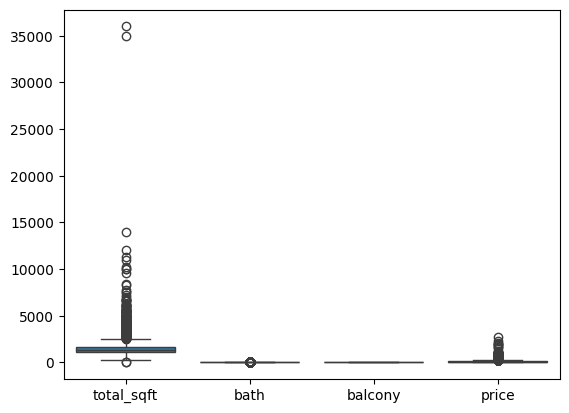

In [29]:
sns.boxplot(df)

In [30]:
df.duplicated().sum()

np.int64(355)

In [31]:
df[df.duplicated()]

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
971,Super built-up Area,Ready To Move,Haralur Road,3 BHK,NRowse,1464.0,3.0,2.0,56.00
1143,Super built-up Area,Ready To Move,Vittasandra,2 BHK,Prlla C,1246.0,2.0,1.0,64.50
1449,Super built-up Area,Ready To Move,Raja Rajeshwari Nagar,3 BHK,GrrvaGr,1693.0,3.0,3.0,57.39
1477,Super built-up Area,Ready To Move,Uttarahalli,3 BHK,Aklia R,1330.0,2.0,1.0,56.00
1668,Super built-up Area,Ready To Move,Bisuvanahalli,3 BHK,Prityel,1075.0,2.0,1.0,45.00
...,...,...,...,...,...,...,...,...,...
13271,Super built-up Area,Ready To Move,Uttarahalli,2 BHK,Ayaya A,1075.0,2.0,1.0,46.76
13274,Super built-up Area,Ready To Move,Budigere,2 BHK,PrityTr,1153.0,2.0,2.0,60.00
13285,Super built-up Area,Ready To Move,VHBCS Layout,2 BHK,OlarkLa,1353.0,2.0,2.0,110.00
13299,Super built-up Area,18-Dec,Whitefield,4 BHK,Prtates,2856.0,5.0,0.0,154.50


In [32]:
df= df.drop_duplicates()

In [33]:
df.duplicated().sum()

np.int64(0)

In [34]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3-Q1
lower_limit = Q1- 1.5 *IQR
upper_limit = Q1+ 1.5 *IQR
print(lower_limit, upper_limit)

-40.0 140.0


In [35]:
print(Q1,Q3)

50.0 110.0


In [36]:
outliers = df[
    (df['price'] < lower_limit) |
    (df['price'] > lower_limit)
    ]
outliers[['total_sqft','location','price']]
    

,total_sqft,location,price
0,1056.0,Electronic City Phase II,39.07
1,2600.0,Chikka Tirupathi,120.00
3,1521.0,Lingadheeranahalli,95.00
5,1170.0,Whitefield,38.00
6,2732.0,Old Airport Road,204.00
...,...,...,...
13309,1675.0,Yeshwanthpur,92.13
13314,1715.0,Green Glen Layout,112.00
13315,3453.0,Whitefield,231.00
13317,1141.0,Raja Rajeshwari Nagar,60.00


In [37]:
len(outliers)

7433

In [38]:
print(' orignal dataset shape:', df.shape)
print('outliers shape:', outliers.shape)

print(df['price'].describe())
print(df['total_sqft'].describe())

 orignal dataset shape: (7433, 9)
outliers shape: (7433, 9)
count    7433.000000
mean      102.724758
std       118.687003
min         8.000000
25%        50.000000
50%        71.000000
75%       110.000000
max      2700.000000
Name: price, dtype: float64
count     7433.000000
mean      1557.868159
std       1001.635891
min         11.000000
25%       1125.000000
50%       1330.000000
75%       1700.000000
max      36000.000000
Name: total_sqft, dtype: float64


Text(0.5, 1.0, 'boxplot of total sq feet')

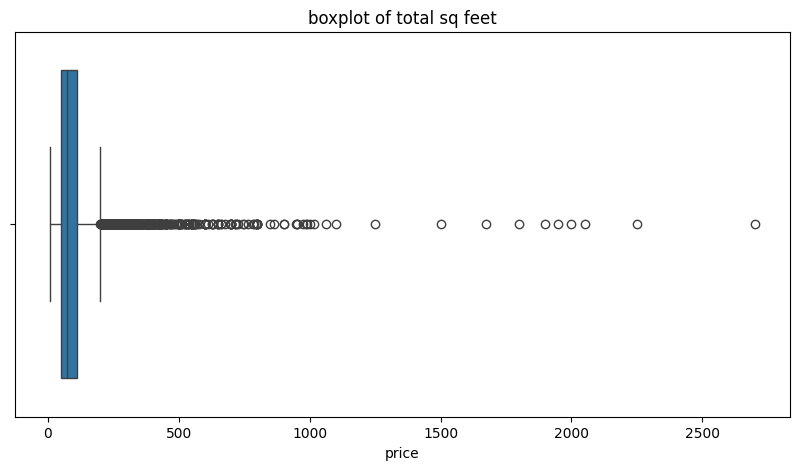

In [39]:
plt.figure(figsize=(10,5))
sns.boxplot(x=df['price'])
plt.title("boxplot of total sq feet")

In [40]:
df_clean = df[
    (df['price'] < lower_limit) |
    (df['price'] > lower_limit)
    ].copy()

print(" Before cleaning:", df.shape)
print("After cleaning:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))

 Before cleaning: (7433, 9)
After cleaning: (7433, 9)
Rows removed: 0


In [41]:
print(df.nlargest(10, 'price')[ 
    ['total_sqft', 'location','price']
    ])

       total_sqft          location   price
3180       8321.0   Shanthala Nagar  2700.0
6421       2940.0      Bommenahalli  2250.0
4162       7000.0            Yemlur  2050.0
7315      11000.0            Yemlur  2000.0
9546      10000.0            Yemlur  1950.0
4929      12000.0            Yemlur  1900.0
9347       9600.0  Ramagondanahalli  1800.0
8682       8400.0            Yemlur  1675.0
10485      7514.0      Rajaji Nagar  1500.0
7855      10200.0        Whitefield  1250.0


In [42]:
df= df.copy()
df['price_per_sqft'] = (df['price']*100000 /
                        df['total_sqft'])
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price,price_per_sqft
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056.0,2.0,1.0,39.07,3699.810606
1,Plot Area,Ready To Move,Chikka Tirupathi,4 BHK,Theanmp,2600.0,5.0,3.0,120.00,4615.384615
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521.0,3.0,1.0,95.00,6245.890861
5,Super built-up Area,Ready To Move,Whitefield,2 BHK,DuenaTa,1170.0,2.0,1.0,38.00,3247.863248
6,Super built-up Area,18-May,Old Airport Road,4 BHK,Jaades,2732.0,4.0,2.0,204.00,7467.057101


In [43]:
df['price_per_sqft'].describe()

count      7433.000000
mean       6091.328225
std        9210.224607
min         371.428571
25%        4340.000000
50%        5398.876404
75%        6776.664702
max      672727.272727
Name: price_per_sqft, dtype: float64

Text(0.5, 1.0, 'outliers in price per sft')

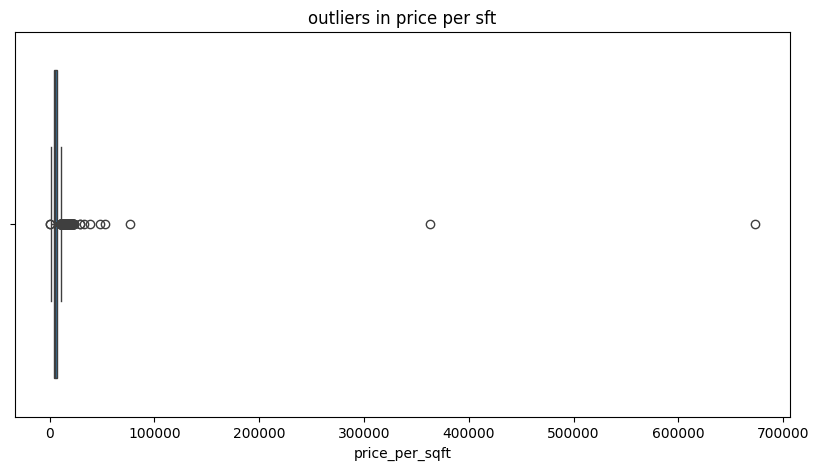

In [44]:
plt.figure(figsize=(10,5))
sns.boxplot(x=df['price_per_sqft'])
plt.title("outliers in price per sft")

In [45]:
print(df.nlargest(10, 'price_per_sqft')[ 
    ['total_sqft', 'location','price', 'price_per_sqft']
    ])

       total_sqft            location   price  price_per_sqft
349         11.00  Suragajakkanahalli    74.0   672727.272727
11558       60.00          Whitefield   218.0   363333.333333
6421      2940.00        Bommenahalli  2250.0    76530.612245
7883      2000.00       Vasanth nagar  1063.0    53150.000000
9195      1496.00          Whitefield   718.0    47994.652406
10570     1800.00     Electronic City   700.0    38888.888889
3180      8321.00     Shanthala Nagar  2700.0    32448.023074
4162      7000.00              Yemlur  2050.0    29285.714286
6667      1030.00  Vittal Mallya Road   300.0    29126.213592
5695      2777.29    Langford Gardens   650.0    23404.109762


In [46]:
df['price_per_sqft'].describe()

count      7433.000000
mean       6091.328225
std        9210.224607
min         371.428571
25%        4340.000000
50%        5398.876404
75%        6776.664702
max      672727.272727
Name: price_per_sqft, dtype: float64

In [47]:
df[df['total_sqft']<100][
    ['total_sqft','location','price','price_per_sqft']]

,total_sqft,location,price,price_per_sqft
349,11.0,Suragajakkanahalli,74.0,672727.272727
11558,60.0,Whitefield,218.0,363333.333333


In [48]:
print("before cleaning:", df.shape)
df= df[df['total_sqft']>=100].copy()
print("after cleaning:", df.shape)

before cleaning: (7433, 10)
after cleaning: (7431, 10)


In [49]:
df['price_per_sqft'] = (df['price']*100000 /
                        df['total_sqft'])
df['price_per_sqft'].describe()

count     7431.000000
mean      5953.543546
std       2800.621262
min        371.428571
25%       4339.934641
50%       5398.749763
75%       6776.175013
max      76530.612245
Name: price_per_sqft, dtype: float64

In [50]:
high_price = df[
    df['price_per_sqft'] > upper_limit][
        ['total_sqft','location','price','price_per_sqft']
        ].sort_values('price_per_sqft', ascending =False).head(10)
   
high_price

,total_sqft,location,price,price_per_sqft
6421,2940.00,Bommenahalli,2250.0,76530.612245
7883,2000.00,Vasanth nagar,1063.0,53150.000000
9195,1496.00,Whitefield,718.0,47994.652406
10570,1800.00,Electronic City,700.0,38888.888889
3180,8321.00,Shanthala Nagar,2700.0,32448.023074
4162,7000.00,Yemlur,2050.0,29285.714286
6667,1030.00,Vittal Mallya Road,300.0,29126.213592
5695,2777.29,Langford Gardens,650.0,23404.109762
12757,2777.29,Langford Gardens,649.0,23368.103439
6190,4750.00,Vasanth nagar,1102.0,23200.000000


In [51]:
df['location'].unique()

array(['Electronic City Phase II', 'Chikka Tirupathi',
       'Lingadheeranahalli', 'Whitefield', 'Old Airport Road',
       'Rajaji Nagar', '7th Phase JP Nagar', 'Sarjapur', 'Mysore Road',
       'Bisuvanahalli', 'Raja Rajeshwari Nagar', 'Ramakrishnappa Layout',
       'Binny Pete', 'Thanisandra', ' Thanisandra', 'Electronic City',
       'Ramagondanahalli', 'Yelahanka', 'Hebbal', 'Kasturi Nagar',
       'Kanakpura Road', 'Kundalahalli', 'Murugeshpalya',
       'Sarjapur  Road', 'Ganga Nagar', 'Doddathoguru', 'Adarsh Nagar',
       'Bhoganhalli', 'Lakshminarayana Pura', 'Begur Road', 'Devanahalli',
       'Varthur', 'Gunjur', 'Hegde Nagar', 'Haralur Road', 'Hennur Road',
       'Cholanayakanahalli', 'Kodanda Reddy Layout', 'EPIP Zone',
       'Dasanapura', 'Kasavanhalli', 'Sanjay nagar', 'Kengeri',
       'Yeshwanthpur', 'Chandapura', 'Kothanur', 'Green View Layout',
       'Shantiniketan Layout', 'Byatarayanapura', 'Akshaya Nagar',
       'LB Shastri Nagar', 'Hormavu', 'Peenya', 'Kud

In [52]:
location_price = df.groupby("location")['price'].mean().sort_values(ascending= False)

In [53]:
location_price.head(10)

location
Yemlur               1605.833333
D Souza Layout       1015.000000
Sindhi Colony         988.000000
Shanthala Nagar       827.500000
Hunasamaranahalli     787.500000
Vasanth nagar         721.500000
Cunningham Road       684.142857
Langford Gardens      649.500000
St. John's Road       630.000000
Sathya Sai Layout     609.250000
Name: price, dtype: float64

In [54]:
location_stats = df.groupby("location")["price"].agg(["mean", "count"]).sort_values(by="mean", ascending=False)
location_stats.head()

,mean,count
location,,
Yemlur,1605.833333,6
D Souza Layout,1015.000000,1
Sindhi Colony,988.000000,1
Shanthala Nagar,827.500000,4
Hunasamaranahalli,787.500000,2


In [55]:
Average_price_by_bhk = df.groupby('size')['price'].mean().sort_values(ascending=False)

In [56]:
Average_price_by_bhk.head(10)

size
8 BHK     1900.000000
5 BHK      511.677778
11 BHK     360.000000
6 BHK      337.555556
4 BHK      294.710783
9 BHK      266.666667
7 BHK      250.000000
18 BHK     200.000000
3 BHK      110.401425
10 BHK     105.000000
Name: price, dtype: float64

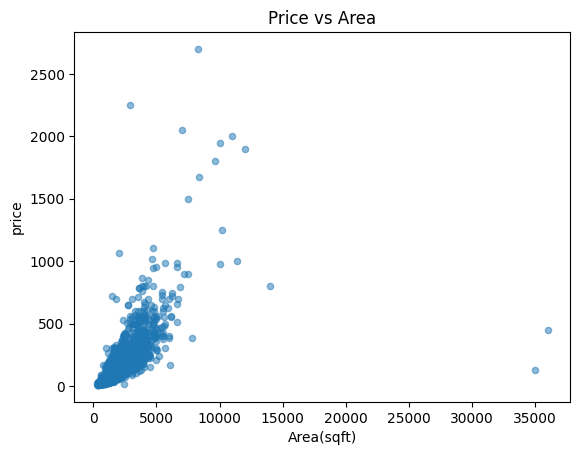

In [57]:
df.plot.scatter(x="total_sqft", y="price", alpha =0.5)
plt.title("Price vs Area")
plt.xlabel("Area(sqft)")
plt.ylabel("price")
plt.show()

In [58]:
df_clean[["total_sqft", "price"]].corr()

,total_sqft,price
total_sqft,1.000000,0.701371
price,0.701371,1.000000


In [59]:
df.dtypes

area_type          object
availability       object
location           object
size               object
society            object
total_sqft        float64
bath              float64
balcony           float64
price             float64
price_per_sqft    float64
dtype: object

In [60]:
price_by_location = df.groupby('location')['price_per_sqft'].mean().sort_values(ascending = False)
price_by_location.head()

location
Vittal Mallya Road    29126.213592
Vasanth nagar         24594.752463
Langford Gardens      23386.106600
D Souza Layout        21903.323263
HAL 2nd Stage         20134.228188
Name: price_per_sqft, dtype: float64

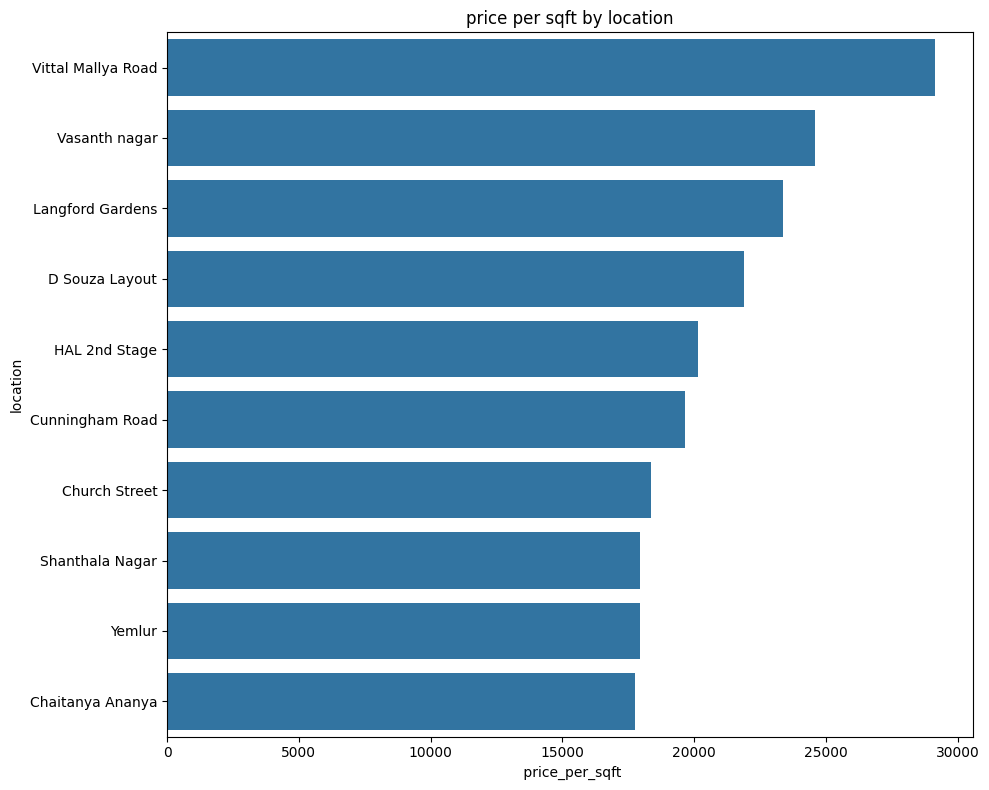

In [61]:
top_10 = price_by_location.head(10)
x= top_10.values
y= top_10.index
plt.figure(figsize=(10,8))
sns.barplot(x= top_10.values,
y= top_10.index)
plt.title("price per sqft by location")
plt.xlabel(' price_per_sqft')
plt.ylabel('location')
plt.tight_layout()
plt.show()


In [62]:
df.head(10)

,area_type,availability,location,size,society,total_sqft,bath,balcony,price,price_per_sqft
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056.0,2.0,1.0,39.07,3699.810606
1,Plot Area,Ready To Move,Chikka Tirupathi,4 BHK,Theanmp,2600.0,5.0,3.0,120.00,4615.384615
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521.0,3.0,1.0,95.00,6245.890861
5,Super built-up Area,Ready To Move,Whitefield,2 BHK,DuenaTa,1170.0,2.0,1.0,38.00,3247.863248
6,Super built-up Area,18-May,Old Airport Road,4 BHK,Jaades,2732.0,4.0,2.0,204.00,7467.057101
7,Super built-up Area,Ready To Move,Rajaji Nagar,4 BHK,Brway G,3300.0,4.0,2.0,600.00,18181.818182
11,Plot Area,Ready To Move,Whitefield,4 BHK,Prrry M,2785.0,5.0,3.0,295.00,10592.459605
12,Super built-up Area,Ready To Move,7th Phase JP Nagar,2 BHK,Shncyes,1000.0,2.0,1.0,38.00,3800.000000
14,Plot Area,Ready To Move,Sarjapur,3 BHK,Skityer,2250.0,3.0,2.0,148.00,6577.777778
15,Super built-up Area,Ready To Move,Mysore Road,2 BHK,PrntaEn,1175.0,2.0,2.0,73.50,6255.319149


In [63]:
bath_price = df.groupby('bath')['price'].mean().sort_values(ascending=True)
bath_price.head(10)

bath
1.0      35.557348
2.0      64.453921
10.0    105.000000
3.0     121.424879
18.0    200.000000
4.0     240.398295
5.0     351.036697
6.0     355.730263
14.0    500.000000
7.0     511.454545
Name: price, dtype: float64

In [64]:
bath_price1 = df.groupby('bath').agg(average_price=('price','mean'), property_count=('price','count'))
bath_price1.head(10)

,average_price,property_count
bath,,
1.0,35.557348,411
2.0,64.453921,4158
3.0,121.424879,2065
4.0,240.398295,484
5.0,351.036697,218
6.0,355.730263,76
7.0,511.454545,11
9.0,712.000000,5
10.0,105.000000,1


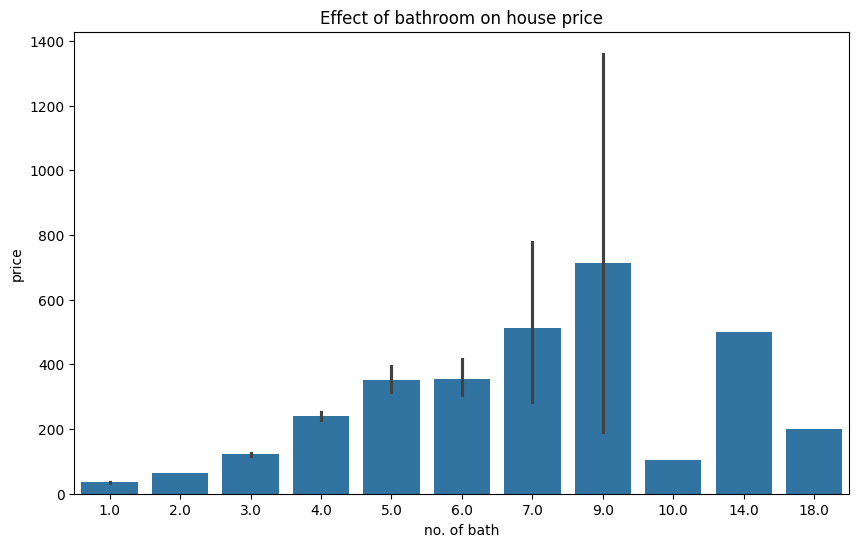

In [65]:
plt.figure(figsize=(10,6))
sns.barplot(df, x=('bath'),y=('price'))
plt.title('Effect of bathroom on house price')
plt.xlabel('no. of bath')
plt.ylabel('price')
plt.show()

In [66]:
bath_price = df.groupby('balcony')['price'].mean().sort_values(ascending=True)
bath_price.head(10)

balcony
1.0     77.806164
0.0     92.167918
2.0    114.874284
3.0    139.016197
Name: price, dtype: float64

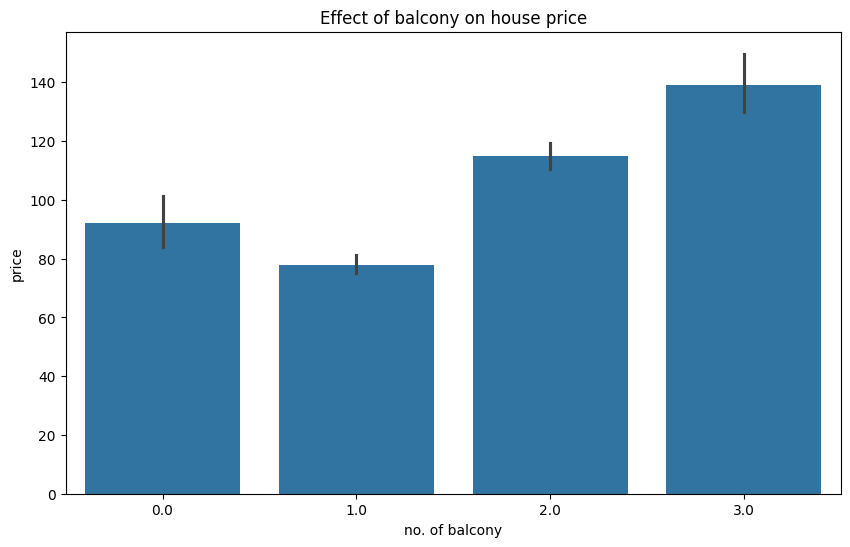

In [67]:
plt.figure(figsize=(10,6))
sns.barplot(df, x=('balcony'),y=('price'))
plt.title('Effect of balcony on house price')
plt.xlabel('no. of balcony')
plt.ylabel('price')
plt.show()

In [70]:
df.to_csv('bengaluru_real_estate_cleaned1.csv', index = False)

In [69]:
i

NameError: name 'i' is not defined